# EDA - Heart disease and Pima diabetes
Exploration only: nothing here feeds the models. Run from the project root or from `notebooks/`.

In [1]:
import sys; sys.path.insert(0, '..')
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd
from src.data import load_heart, load_diabetes
sns.set_theme(style='whitegrid')
heart, diab = load_heart(), load_diabetes()
print(heart.shape, diab.shape)

Matplotlib is building the font cache; this may take a moment.


(918, 13) (768, 9)


## 1. Heart: size, sources, class balance
The four hospitals differ a lot in prevalence (Switzerland ~93% positive vs Cleveland ~46%). This is exactly why cross-source testing matters.

In [2]:
print(heart.groupby('Source').HeartDisease.agg(n='size', positive_rate='mean').round(3))
heart.describe().round(1)

                 n  positive_rate
Source                           
Cleveland      303          0.459
Hungarian      293          0.362
Switzerland    123          0.935
VA Long Beach  199          0.744


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.0,858.0,717.0,828.0,863.0,856.0,918.0
mean,53.5,132.3,246.9,0.2,137.5,0.9,0.6
std,9.4,18.5,58.6,0.4,25.9,1.1,0.5
min,28.0,80.0,85.0,0.0,60.0,-2.6,0.0
25%,47.0,120.0,210.0,0.0,120.0,0.0,0.0
50%,54.0,130.0,240.0,0.0,140.0,0.5,1.0
75%,60.0,140.0,277.0,0.0,157.0,1.5,1.0
max,77.0,200.0,603.0,1.0,202.0,6.2,1.0


## 2. Heart: missing values
Cholesterol has many zeros in the raw data (impossible), which we recoded to NaN. `ST_Slope` is missing for ~1/3 of rows. All imputation happens inside the CV pipeline.

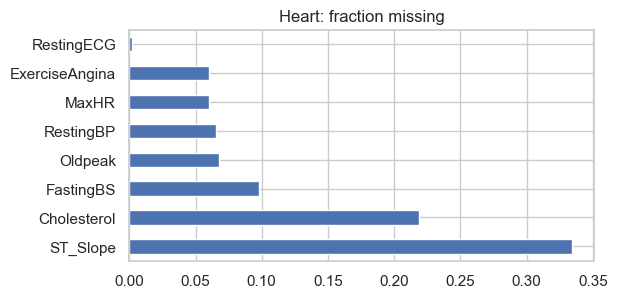

Source
Cleveland        0.00
Hungarian        0.08
Switzerland      1.00
VA Long Beach    0.28
Name: CholMissing, dtype: float64


In [3]:
miss = heart.isna().mean().sort_values(ascending=False)
miss[miss>0].plot.barh(figsize=(6,3), title='Heart: fraction missing'); plt.show()
print(heart.assign(CholMissing=heart.Cholesterol.isna()).groupby('Source').CholMissing.mean().round(2))

## 3. Heart: feature vs outcome

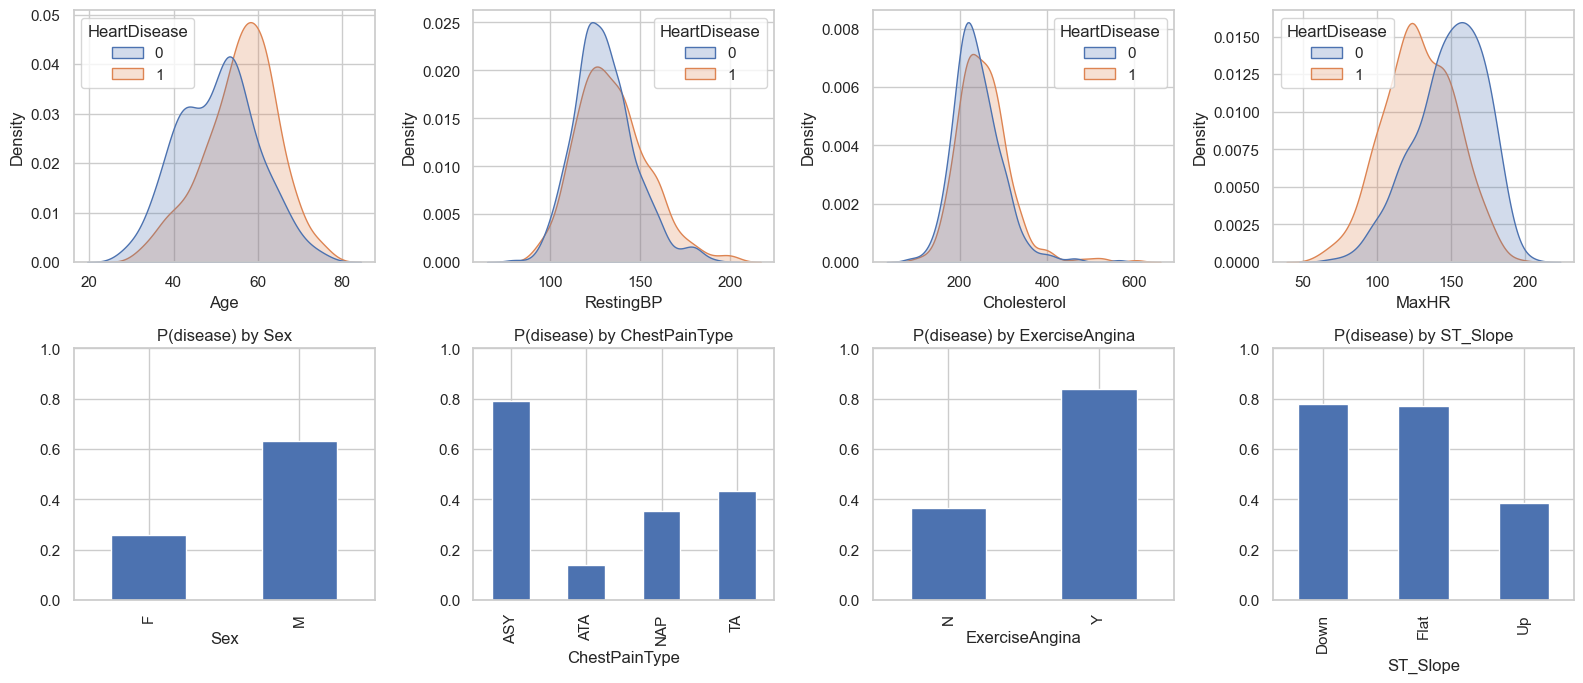

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, c in zip(ax.ravel()[:4], ['Age','RestingBP','Cholesterol','MaxHR']):
    sns.kdeplot(data=heart, x=c, hue='HeartDisease', common_norm=False, fill=True, ax=a)
for a, c in zip(ax.ravel()[4:], ['Sex','ChestPainType','ExerciseAngina','ST_Slope']):
    heart.groupby(c).HeartDisease.mean().plot.bar(ax=a, title=f'P(disease) by {c}'); a.set_ylim(0,1)
plt.tight_layout(); plt.show()

## 4. Diabetes: hidden zeros
Pima encodes missing as 0 for Glucose, BloodPressure, SkinThickness, Insulin, BMI. We treat them as missing.

In [5]:
raw0 = pd.read_csv('../data/raw/pima.csv', header=None, names=diab.columns)
zero_counts = (raw0[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']]==0).sum()
print('zeros in raw file:', zero_counts.to_dict())
print('NaNs after recoding:', diab.isna().sum()[lambda s:s>0].to_dict())
print('positive rate: %.3f' % diab.Outcome.mean())

zeros in raw file: {'Glucose': 5, 'BloodPressure': 35, 'SkinThickness': 227, 'Insulin': 374, 'BMI': 11}
NaNs after recoding: {'Glucose': 5, 'BloodPressure': 35, 'SkinThickness': 227, 'Insulin': 374, 'BMI': 11}
positive rate: 0.349


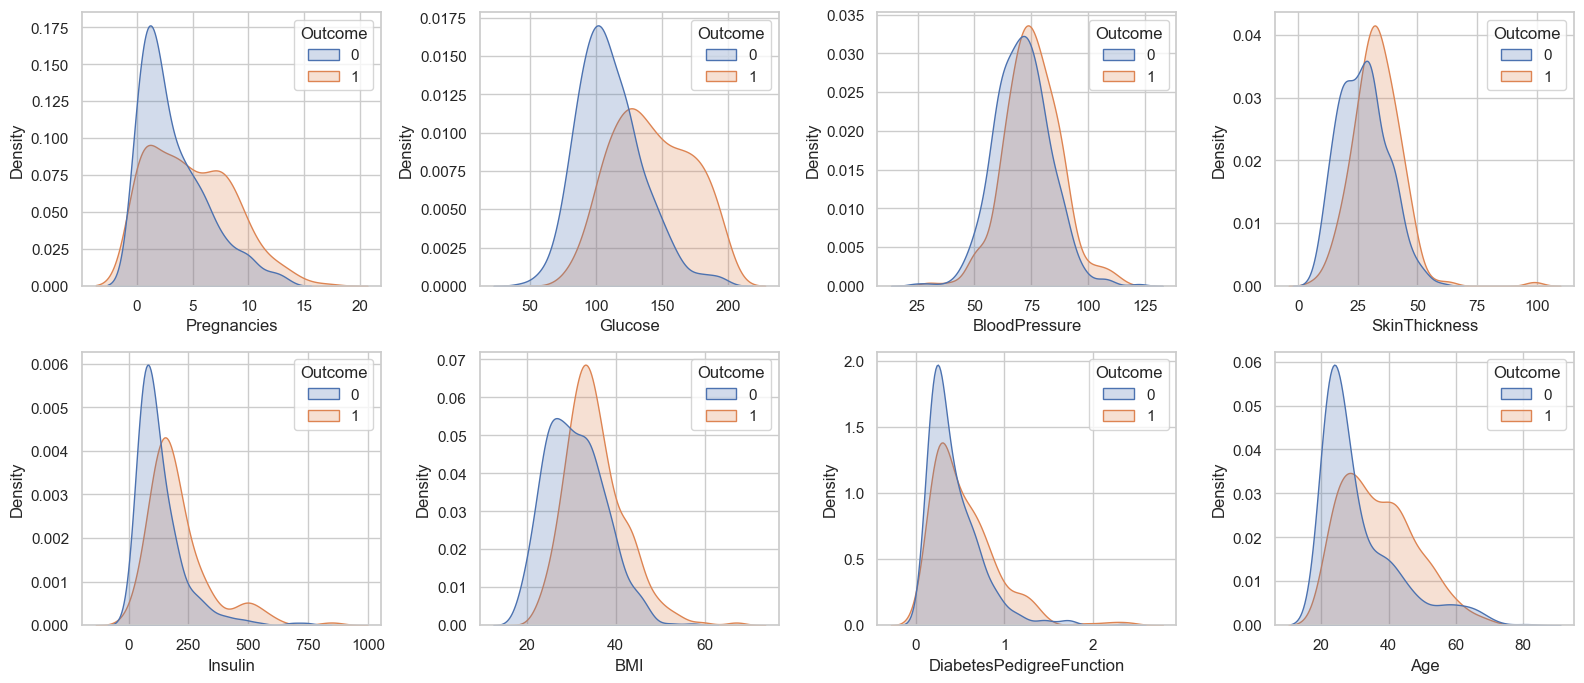

In [6]:
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, c in zip(ax.ravel(), [c for c in diab.columns if c!='Outcome']):
    sns.kdeplot(data=diab, x=c, hue='Outcome', common_norm=False, fill=True, ax=a)
plt.tight_layout(); plt.show()

## 5. Correlations

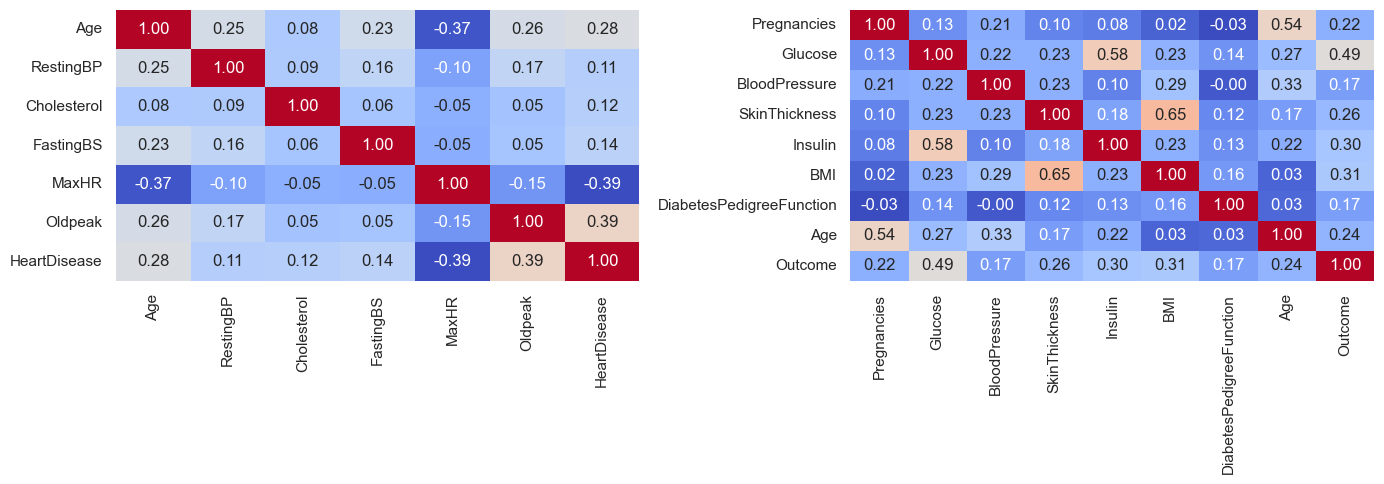

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(heart.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[0], cbar=False)
sns.heatmap(diab.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1], cbar=False)
plt.tight_layout(); plt.show()

## Take-aways
* Both datasets have imbalance-light classes but heavy hidden missingness -> imputation must live inside the pipeline.
* Heart sources differ in prevalence and missingness -> expect a drop in cross-source performance.
* Glucose (diabetes) and ChestPainType/ST_Slope/ExerciseAngina (heart) look like the strongest signals; the explanation methods should reflect that.